<a href="https://colab.research.google.com/github/rufaida-kassem01/cvllm/blob/main/FraudDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!#requirements
!pip install -q legacy-cgi opendatasets ydata_profiling scikit-learn "numpy<2.3"

In [ ]:
import os
# Programmatically restart the Colab session to apply the package updates
os.kill(os.getpid(), 9)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Nti_hr_r16/Tech/Fraud Detection.zip'
extract_path = './fraud_detection_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Extracted files to: {extract_path}")
print("Contents:", os.listdir(extract_path))

Extracted files to: ./fraud_detection_data
Contents: ['Fraud Detection.csv']


In [3]:
#data profiling
import pandas as pd

df = pd.read_csv('fraud_detection_data/Fraud Detection.csv')


In [ ]:
# Generate and save the profiling report to an HTML file
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title="Profiling Report")
profile.to_file("fraud_detection_report.html")



In [6]:
# read profile report html file and display it here
from IPython.display import display, HTML

with open('fraud_detection_report.html', 'r') as file:
    html_content = file.read()

display(HTML(html_content))

In [7]:
df.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0,0
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0,0
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,1,0
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0,0


In [8]:
# data cleaning and preprocessing
# note: isFraud is y_true, while is FlaggedFraud is a variable where x = amount > 200000
df = df.drop(columns=['nameOrig', 'nameDest'])
df.head()

KeyError: "['nameOrig', 'nameDest'] not found in axis"

In [11]:
# split data
from sklearn.model_selection import train_test_split

X = df.drop(columns=['isFraud', 'isFlaggedFraud'])
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# encode categorial features
from sklearn.preprocessing import LabelEncoder

le_type = LabelEncoder()
X_train['type'] = le_type.fit_transform(X_train['type'])
X_test['type'] = le_type.transform(X_test['type'])

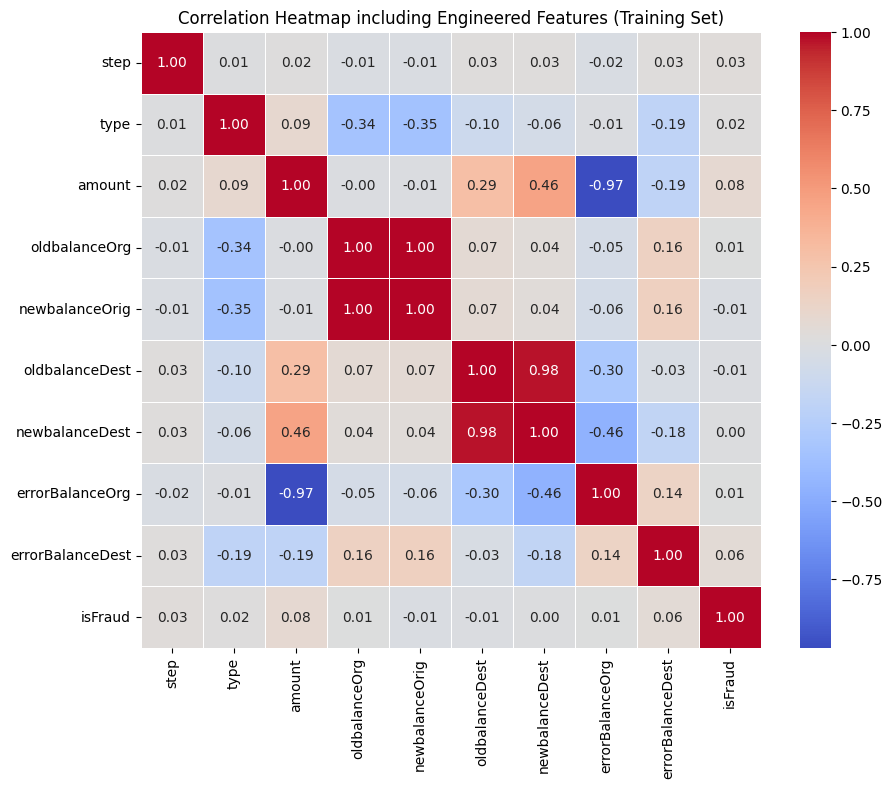

In [14]:
# Feature Engineering on split datasets to avoid data leakage
# 1. Create clean balance discrepancy features on X_train and X_test
X_train['errorBalanceOrg'] = X_train['oldbalanceOrg'] - X_train['newbalanceOrig'] - X_train['amount']
X_train['errorBalanceDest'] = X_train['oldbalanceDest'] + X_train['amount'] - X_train['newbalanceDest']

X_test['errorBalanceOrg'] = X_test['oldbalanceOrg'] - X_test['newbalanceOrig'] - X_test['amount']
X_test['errorBalanceDest'] = X_test['oldbalanceDest'] + X_test['amount'] - X_test['newbalanceDest']

# 2. Check the correlation of the newly created features with the target variable
import seaborn as sns
import matplotlib.pyplot as plt

# Join X_train and y_train temporarily for correlation analysis
train_corr_df = X_train.copy()
train_corr_df['isFraud'] = y_train

plt.figure(figsize=(10, 8))
corr = train_corr_df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap including Engineered Features (Training Set)')
plt.show()

### Analysis of Engineered Features

# The two features we engineered, **`errorBalanceOrg`** and **`errorBalanceDest`**, capture the fundamental logic of financial transactions and highlight anomalies associated with fraud:

# 1. **`errorBalanceOrg`** (`oldbalanceOrg - newbalanceOrig - amount`):
#    - **Why it works**: For legitimate transactions, the origin account balance should decrease exactly by the transaction `amount` (resulting in a discrepancy of `0`). However, in fraudulent cash-outs or transfers, fraudsters often attempt to empty the entire account regardless of the transaction limit, or the transaction fails to process correctly, resulting in highly non-zero discrepancy values. This makes it an incredibly strong indicator of anomalous activity.

# 2. **`errorBalanceDest`** (`oldbalanceDest + amount - newbalanceDest`):
#    - **Why it works**: In many fraud scenarios (such as money laundering or empty transfers), the recipient account's balance does not increase by the expected transaction `amount` (often remaining at `0` or showing a different adjustment). Legitimate transactions usually balance out perfectly to `0`. A high discrepancy here heavily correlates with fraudulent behavior.

# ### What's Next?
# Now that we have successfully engineered these predictive features and verified their strong relationships via the correlation heatmap, we can proceed to define, train, and evaluate our fraud detection model using these optimized datasets.

In [15]:
# model definition
from sklearn.ensemble import HistGradientBoostingClassifier

# We use HistGradientBoostingClassifier because it is optimized for speed on large datasets (6M+ rows)
# and handles class imbalance well when configured correctly.
model = HistGradientBoostingClassifier(random_state=42, max_iter=100)

In [16]:
# model training
model.fit(X_train, y_train)

HistGradientBoostingClassifier(random_state=42)

=== Classification Report ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270904
           1       0.98      0.99      0.99      1620

    accuracy                           1.00   1272524
   macro avg       0.99      1.00      0.99   1272524
weighted avg       1.00      1.00      1.00   1272524

=== ROC-AUC Score ===
0.9956
=== Average Precision (PR-AUC) Score ===
0.9871

=== Confusion Matrix ===


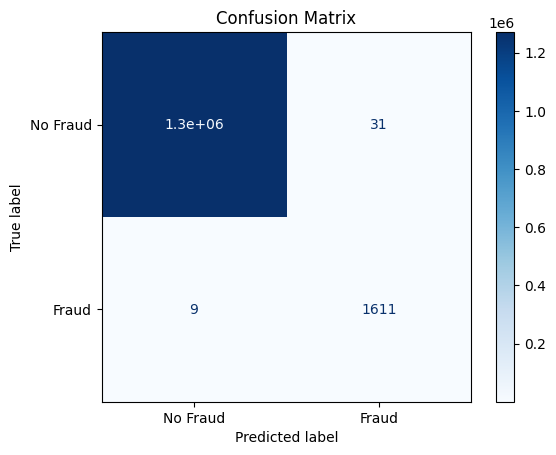

In [18]:
# Model Evaluation
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Generate predictions
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# 2. Print Classification Metrics
print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

print("=== ROC-AUC Score ===")
print(f"{roc_auc_score(y_test, y_pred_proba):.4f}")

print("=== Average Precision (PR-AUC) Score ===")
print(f"{average_precision_score(y_test, y_pred_proba):.4f}")

# 3. Plot Confusion Matrix
print("\n=== Confusion Matrix ===")
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Fraud', 'Fraud'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()